In [1]:
import datetime
import json
from pathlib import Path

import numpy as np
import pandas as pd

from alpha_engine.backtest import run_backtest
from alpha_engine.data import Data
from alpha_engine.eigen import EigenPortfolio, build_portfolio, corr_eigh_method, cov_eigh_method
from alpha_engine.plotting import plot_backtest_result

In [ ]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

TEST_YEARS = range(1999, 2026)  # range(1999, 2027)
RANKS = range(26)
TOP_N = 20
TARGET_SYMBOL_COUNT = 2000


def training_window_for_test_year(test_year: int) -> tuple[datetime.date, datetime.date]:
    return datetime.date(test_year - 2, 12, 1), datetime.date(test_year - 1, 12, 1)


def test_window_for_year(test_year: int) -> tuple[datetime.date, datetime.date]:
    return datetime.date(test_year, 1, 1), datetime.date(test_year + 1, 1, 1)


def daily_returns_from_cumulative(cumulative: pd.Series) -> pd.Series:
    daily_returns = cumulative.pct_change()
    daily_returns.iloc[0] = cumulative.iloc[0] - 1.0
    return daily_returns


def annualized_return(cumulative: pd.Series, trading_days: int = 252) -> float:
    periods = len(cumulative)
    if periods == 0:
        return float("nan")
    total_return = float(cumulative.iloc[-1])
    return total_return ** (periods / periods) - 1.0


def sharpe_ratio(cumulative: pd.Series, trading_days: int = 252) -> float:
    daily_returns = daily_returns_from_cumulative(cumulative).dropna()
    if daily_returns.empty:
        return float("nan")
    volatility = float(daily_returns.std(ddof=0))
    if np.isclose(volatility, 0.0):
        return float("nan")
    return float(np.sqrt(trading_days) * daily_returns.mean() / volatility)

In [3]:
summary_records: list[dict[str, object]] = []
position_records: list[dict[str, object]] = []

for test_year in TEST_YEARS:
    print(test_year)
    train_start, train_end = training_window_for_test_year(test_year)
    test_start, test_end = test_window_for_year(test_year)

    try:
        data = Data.load_strategy(
            train_start,
            train_end,
            target_symbol_count=TARGET_SYMBOL_COUNT,
        )
        backtest = data.load_backtest(test_start, test_end)
    except Exception as exc:
        summary_records.append(
            {
                "test_year": test_year,
                "train_start": train_start.isoformat(),
                "train_end": train_end.isoformat(),
                "test_start": test_start.isoformat(),
                "test_end": test_end.isoformat(),
                "target_symbol_count": TARGET_SYMBOL_COUNT,
                "top_n": TOP_N,
                "rank": pd.NA,
                "benchmark_symbol": pd.NA,
                "status": "load_error",
                "error": str(exc),
                "strategy_annualized_return": np.nan,
                "strategy_sharpe_ratio": np.nan,
                "benchmark_annualized_return": np.nan,
                "benchmark_sharpe_ratio": np.nan,
            }
        )
        continue

    for rank in RANKS:
        try:
            portfolio = build_portfolio(
                data,
                method=corr_eigh_method,
                rank=rank,
                top_n=TOP_N,
            )
            result = run_backtest(portfolio, backtest)
            cumulative = result.cumulative_returns
            sorted_weights = portfolio.weights.sort_values(ascending=False)

            strategy_annualized = annualized_return(cumulative["strategy"])
            strategy_sharpe = sharpe_ratio(cumulative["strategy"])

            for benchmark_symbol in backtest.benchmark_symbols:
                summary_records.append(
                    {
                        "test_year": test_year,
                        "train_start": train_start.isoformat(),
                        "train_end": train_end.isoformat(),
                        "test_start": test_start.isoformat(),
                        "test_end": test_end.isoformat(),
                        "target_symbol_count": TARGET_SYMBOL_COUNT,
                        "top_n": TOP_N,
                        "rank": rank,
                        "benchmark_symbol": benchmark_symbol,
                        "status": "ok",
                        "error": "",
                        "strategy_annualized_return": strategy_annualized,
                        "strategy_sharpe_ratio": strategy_sharpe,
                        "benchmark_annualized_return": annualized_return(
                            cumulative[benchmark_symbol]
                        ),
                        "benchmark_sharpe_ratio": sharpe_ratio(cumulative[benchmark_symbol]),
                    }
                )

            for symbol, weight in sorted_weights.items():
                position_records.append(
                    {
                        "test_year": test_year,
                        "train_start": train_start.isoformat(),
                        "train_end": train_end.isoformat(),
                        "test_start": test_start.isoformat(),
                        "test_end": test_end.isoformat(),
                        "target_symbol_count": TARGET_SYMBOL_COUNT,
                        "top_n": TOP_N,
                        "rank": rank,
                        "symbol": symbol,
                        "weight": float(weight),
                    }
                )
        except Exception as exc:
            summary_records.append(
                {
                    "test_year": test_year,
                    "train_start": train_start.isoformat(),
                    "train_end": train_end.isoformat(),
                    "test_start": test_start.isoformat(),
                    "test_end": test_end.isoformat(),
                    "target_symbol_count": TARGET_SYMBOL_COUNT,
                    "top_n": TOP_N,
                    "rank": rank,
                    "benchmark_symbol": pd.NA,
                    "status": "portfolio_error",
                    "error": str(exc),
                    "strategy_annualized_return": np.nan,
                    "strategy_sharpe_ratio": np.nan,
                    "benchmark_annualized_return": np.nan,
                    "benchmark_sharpe_ratio": np.nan,
                }
            )

summary_df = pd.DataFrame(summary_records).sort_values(
    ["test_year", "rank", "benchmark_symbol"],
    na_position="last",
)
positions_df = pd.DataFrame(position_records).sort_values(
    ["test_year", "rank", "weight"],
    ascending=[True, True, False],
)

timestamp = datetime.datetime.now(datetime.UTC).strftime("%Y%m%dT%H%M%SZ")
summary_path = RESULTS_DIR / f"cov_eigh_rank_sweep_summary_{timestamp}.csv"
positions_path = RESULTS_DIR / f"cov_eigh_rank_sweep_positions_{timestamp}.csv"
manifest_path = RESULTS_DIR / f"cov_eigh_rank_sweep_manifest_{timestamp}.json"

summary_df.to_csv(summary_path, index=False)
positions_df.to_csv(positions_path, index=False)
manifest_path.write_text(
    json.dumps(
        {
            "summary_path": str(summary_path),
            "positions_path": str(positions_path),
            "test_year_start": min(TEST_YEARS),
            "test_year_end": max(TEST_YEARS),
            "rank_start": min(RANKS),
            "rank_end": max(RANKS),
            "top_n": TOP_N,
            "target_symbol_count": TARGET_SYMBOL_COUNT,
        },
        indent=2,
    ),
    encoding="utf-8",
)

print(f"Saved {len(summary_df)} summary rows to {summary_path}")
print(f"Saved {len(positions_df)} position rows to {positions_path}")
summary_df.head()

1999
2000
2001
2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021
2022
2023
2024
2025
Saved 1224 summary rows to results\cov_eigh_rank_sweep_summary_20261003T013125Z.csv
Saved 5720 position rows to results\cov_eigh_rank_sweep_positions_20261003T013125Z.csv


,test_year,train_start,train_end,test_start,test_end,target_symbol_count,top_n,rank,benchmark_symbol,status,error,strategy_annualized_return,strategy_sharpe_ratio,benchmark_annualized_return,benchmark_sharpe_ratio
0,1999,1997-12-01,1998-12-01,1999-01-01,2000-01-01,2000,20,<NA>,NaN,load_error,single positional indexer is out-of-bounds,NaN,NaN,NaN,NaN
1,2000,1998-12-01,1999-12-01,2000-01-01,2001-01-01,2000,20,<NA>,NaN,load_error,single positional indexer is out-of-bounds,NaN,NaN,NaN,NaN
2,2001,1999-12-01,2000-12-01,2001-01-01,2002-01-01,2000,20,0,IWV,ok,,-0.083888,0.186795,-0.082190,-0.293371
4,2001,1999-12-01,2000-12-01,2001-01-01,2002-01-01,2000,20,0,QQQ,ok,,-0.083888,0.186795,-0.267351,-0.324453
3,2001,1999-12-01,2000-12-01,2001-01-01,2002-01-01,2000,20,0,SPY,ok,,-0.083888,0.186795,-0.099448,-0.377175


In [4]:
latest_summary = max(
    RESULTS_DIR.glob("cov_eigh_rank_sweep_summary_*.csv"),
    key=lambda path: path.stat().st_mtime,
    default=None,
)
latest_positions = max(
    RESULTS_DIR.glob("cov_eigh_rank_sweep_positions_*.csv"),
    key=lambda path: path.stat().st_mtime,
    default=None,
)

reloaded_summary = pd.read_csv(latest_summary) if latest_summary else pd.DataFrame()
reloaded_positions = pd.read_csv(latest_positions) if latest_positions else pd.DataFrame()

print(latest_summary)
print(latest_positions)
reloaded_summary.head()

results\cov_eigh_rank_sweep_summary_20261003T013125Z.csv
results\cov_eigh_rank_sweep_positions_20261003T013125Z.csv


,test_year,train_start,train_end,test_start,test_end,target_symbol_count,top_n,rank,benchmark_symbol,status,error,strategy_annualized_return,strategy_sharpe_ratio,benchmark_annualized_return,benchmark_sharpe_ratio
0,1999,1997-12-01,1998-12-01,1999-01-01,2000-01-01,2000,20,NaN,NaN,load_error,single positional indexer is out-of-bounds,NaN,NaN,NaN,NaN
1,2000,1998-12-01,1999-12-01,2000-01-01,2001-01-01,2000,20,NaN,NaN,load_error,single positional indexer is out-of-bounds,NaN,NaN,NaN,NaN
2,2001,1999-12-01,2000-12-01,2001-01-01,2002-01-01,2000,20,0.0,IWV,ok,NaN,-0.083888,0.186795,-0.082190,-0.293371
3,2001,1999-12-01,2000-12-01,2001-01-01,2002-01-01,2000,20,0.0,QQQ,ok,NaN,-0.083888,0.186795,-0.267351,-0.324453
4,2001,1999-12-01,2000-12-01,2001-01-01,2002-01-01,2000,20,0.0,SPY,ok,NaN,-0.083888,0.186795,-0.099448,-0.377175


In [5]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

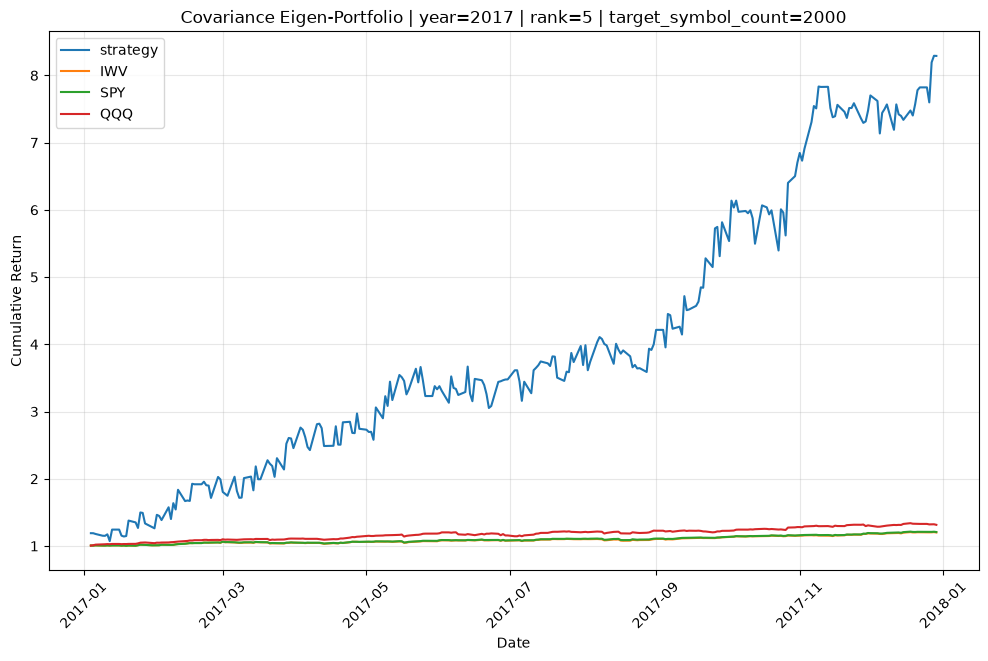

In [ ]:
def plot_saved_result(
    test_year: int,
    rank: int,
    target_symbol_count: int | None = None,
    *,
    target_symbol: int | None = None,
    positions: pd.DataFrame | None = None,
    summary: pd.DataFrame | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    selected_target_symbol_count = target_symbol_count
    if selected_target_symbol_count is None:
        selected_target_symbol_count = target_symbol
    if selected_target_symbol_count is None:
        raise ValueError("Provide target_symbol_count or target_symbol to select a saved result.")

    active_positions = positions if positions is not None else reloaded_positions
    active_summary = summary if summary is not None else reloaded_summary
    if active_positions.empty:
        raise ValueError("No saved positions are loaded.")

    selected_positions = active_positions.loc[
        (active_positions["test_year"] == test_year)
        & (active_positions["rank"] == rank)
        & (active_positions["target_symbol_count"] == selected_target_symbol_count)
    ].copy()
    if selected_positions.empty:
        raise ValueError(
            "No saved portfolio matched the requested year, rank, and target_symbol_count."
        )

    selected_positions = selected_positions.sort_values("weight", ascending=False)
    weights = pd.Series(
        selected_positions["weight"].to_numpy(dtype=float),
        index=selected_positions["symbol"].astype(str),
        name="port_wt",
    )
    portfolio = EigenPortfolio(
        symbols=tuple(weights.index),
        weights=weights,
        method="corr_eigh_method",
        rank=rank,
    )

    train_start, train_end = training_window_for_test_year(test_year)
    test_start, test_end = test_window_for_year(test_year)
    data = Data.load_strategy(
        train_start,
        train_end,
        target_symbol_count=int(selected_target_symbol_count),
    )
    backtest = data.load_backtest(test_start, test_end)
    result = run_backtest(portfolio, backtest)

    selected_summary = pd.DataFrame()
    if not active_summary.empty:
        selected_summary = active_summary.loc[
            (active_summary["test_year"] == test_year)
            & (active_summary["rank"] == rank)
            & (active_summary["target_symbol_count"] == selected_target_symbol_count)
        ].copy()

    plot_backtest_result(
        result,
        title=(
            f"Covariance Eigen-Portfolio | year={test_year} | rank={rank} | "
            f"target_symbol_count={selected_target_symbol_count}"
        ),
    )
    return selected_summary, selected_positions


selected_summary, selected_positions = plot_saved_result(
    test_year=2017,
    rank=5,
    target_symbol_count=2000,
    # target_symbol=2000,
    # positions=positions_df,
    # summary=summary_df,
)

# print(selected_summary)
# print(selected_positions.head(20))